# Оценка эффекта email-рассылок

Основная метрика — средняя сумма покупок за две недели на одного клиента, включая клиентов с нулевыми расходами.

Проверю два сравнения: `Mens E-Mail` против `No E-Mail` и `Womens E-Mail` против `No E-Mail`. Для каждого сравнения нулевая гипотеза — средние расходы равны. Альтернативная — средние расходы различаются.

Для каждого варианта оценю абсолютный эффект в долларах на клиента и построю 95%-й доверительный интервал. Для проверки гипотез использую двусторонний критерий Уэлча и поправку Холма на два сравнения при общем уровне значимости 0,05. Посещения и конверсию в покупку рассмотрю как дополнительные показатели.

In [2]:
from pathlib import Path

import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

df = pd.read_csv(root / "data" / "raw" / "hillstrom.csv")

print(f"Загружено клиентов: {len(df):,}")

Загружено клиентов: 64,000


In [3]:
group_order = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]

group_metrics = (
    df.groupby("segment")
    .agg(
        clients=("segment", "size"),
        visitors=("visit", "sum"),
        buyers=("conversion", "sum"),
        spend_per_client=("spend", "mean"),
    )
    .reindex(group_order)
)

group_metrics["visit_rate_pct"] = (
    group_metrics["visitors"] / group_metrics["clients"] * 100
)
group_metrics["conversion_rate_pct"] = (
    group_metrics["buyers"] / group_metrics["clients"] * 100
)

display(group_metrics.round(4))

,clients,visitors,buyers,spend_per_client,visit_rate_pct,conversion_rate_pct
segment,,,,,,
No E-Mail,21306,2262,122,0.6528,10.6167,0.5726
Mens E-Mail,21307,3894,267,1.4226,18.2757,1.2531
Womens E-Mail,21387,3238,189,1.0772,15.1400,0.8837


По таблице средние расходы составили $0,6528 в контроле, $1,4226 в группе мужской рассылки и $1,0772 в группе женской. Наблюдаемый эффект относительно контроля — +$0,7698 и +$0,4244 на клиента соответственно. Теперь оценим, насколько точны эти оценки.

### Эффект рассылок на средние расходы

Сравню каждую рассылку с контролем по средним расходам на клиента за две недели. Для каждого сравнения рассчитаю разницу средних, индивидуальный 95%-й доверительный интервал и p-value двустороннего критерия Уэлча. К двум p-value применю поправку Холма.

In [4]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

control_spend = df.loc[df["segment"] == "No E-Mail", "spend"]
comparisons = []

for group in ["Mens E-Mail", "Womens E-Mail"]:
    treatment_spend = df.loc[df["segment"] == group, "spend"]

    test = ttest_ind(
        treatment_spend,
        control_spend,
        equal_var=False,
        alternative="two-sided",
    )
    ci = test.confidence_interval(confidence_level=0.95)

    comparisons.append({
        "group": group,
        "effect_usd": treatment_spend.mean() - control_spend.mean(),
        "ci95_low": ci.low,
        "ci95_high": ci.high,
        "p_value": test.pvalue,
    })

ab_results = pd.DataFrame(comparisons).set_index("group")

reject_null, adjusted_p_values, _, _ = multipletests(
    ab_results["p_value"],
    alpha=0.05,
    method="holm",
)

ab_results["p_value_holm"] = adjusted_p_values
ab_results["reject_null"] = reject_null

display(ab_results.round({
    "effect_usd": 4,
    "ci95_low": 4,
    "ci95_high": 4,
}))

,effect_usd,ci95_low,ci95_high,p_value,p_value_holm,reject_null
group,,,,,,
Mens E-Mail,0.7698,0.4851,1.0545,1.163815e-07,2.327630e-07,True
Womens E-Mail,0.4244,0.1690,0.6799,1.129397e-03,1.129397e-03,True


### Результаты A/B-теста

За две недели мужская рассылка увеличила средние расходы на **$0,77 на клиента** относительно контроля (95%-й ДИ от $0,49 до $1,05). Для женской рассылки прирост составил **$0,42 на клиента** (95%-й ДИ от $0,17 до $0,68).

Оба эффекта статистически значимы после поправки Холма. Чтобы выяснить, различается ли эффективность двух рассылок, нужно сравнить их напрямую.

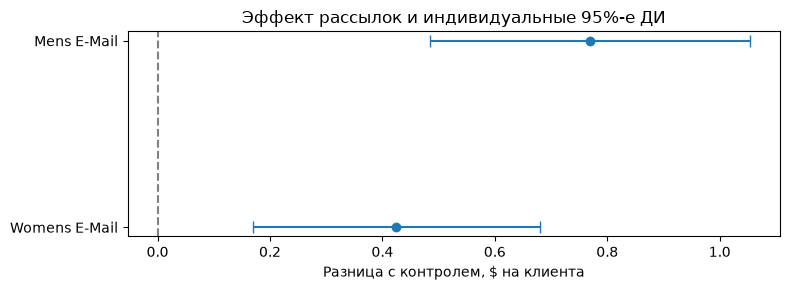

In [5]:
import matplotlib.pyplot as plt

effects = ab_results["effect_usd"]
errors = [
    effects - ab_results["ci95_low"],
    ab_results["ci95_high"] - effects,
]
positions = range(len(ab_results))

fig, ax = plt.subplots(figsize=(8, 3))
ax.errorbar(effects, positions, xerr=errors, fmt="o", capsize=4)
ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks(positions, labels=ab_results.index)
ax.invert_yaxis()
ax.set_xlabel("Разница с контролем, $ на клиента")
ax.set_title("Эффект рассылок и индивидуальные 95%-е ДИ")
plt.tight_layout()
plt.show()

Обе рассылки увеличили средние расходы на клиента по сравнению с группой без письма. На графике обе точки и оба доверительных интервала находятся правее нуля.

### Проверка устойчивости результатов с помощью бутстрэпа

Для каждой рассылки построю 95%-й бутстрэп-интервал разницы средних расходов с контролем. Использую 5 000 повторных выборок клиентов с возвращением внутри каждой группы. Сравню полученные границы с интервалами Уэлча.

In [6]:
import numpy as np
from scipy.stats import bootstrap


def difference_in_means(treatment, control, axis):
    return treatment.mean(axis=axis) - control.mean(axis=axis)


rng = np.random.default_rng(42)
bootstrap_intervals = []

for group in ab_results.index:
    treatment_spend = df.loc[df["segment"] == group, "spend"].to_numpy()

    result = bootstrap(
        (treatment_spend, control_spend.to_numpy()),
        difference_in_means,
        paired=False,
        n_resamples=5_000,
        batch=64,
        confidence_level=0.95,
        method="percentile",
        rng=rng,
    )

    bootstrap_intervals.append({
        "group": group,
        "bootstrap_low": result.confidence_interval.low,
        "bootstrap_high": result.confidence_interval.high,
    })

bootstrap_results = pd.DataFrame(bootstrap_intervals).set_index("group")

interval_comparison = (
    ab_results[["effect_usd", "ci95_low", "ci95_high"]]
    .join(bootstrap_results)
)

display(interval_comparison.round(4))

,effect_usd,ci95_low,ci95_high,bootstrap_low,bootstrap_high
group,,,,,
Mens E-Mail,0.7698,0.4851,1.0545,0.4965,1.0476
Womens E-Mail,0.4244,0.1690,0.6799,0.1767,0.6910


Индивидуальный 95%-й бутстрэп-интервал прироста расходов составил **от $0,50 до $1,05 на клиента** для рассылки с мужским ассортиментом и **от $0,18 до $0,69** для рассылки с женским ассортиментом.

Границы близки к интервалам Уэлча. При обоих способах расчёта интервалы целиком выше нуля, поэтому вывод о положительном эффекте каждой рассылки относительно контроля сохраняется.

In [7]:
# сравним посещаемость и конверсию
rate_columns = ["visit_rate_pct", "conversion_rate_pct"]
rates = group_metrics[rate_columns]

secondary_effects = (
    rates.loc[["Mens E-Mail", "Womens E-Mail"]]
    .subtract(rates.loc["No E-Mail"], axis="columns")
    .rename(columns={
        "visit_rate_pct": "Посещаемость, разница в п.п.",
        "conversion_rate_pct": "Конверсия, разница в п.п.",
    })
)

display(secondary_effects.round(2))

,"Посещаемость, разница в п.п.","Конверсия, разница в п.п."
segment,,
Mens E-Mail,7.66,0.68
Womens E-Mail,4.52,0.31


In [8]:
# Если дополнительный доллар покупок приносит 30 центов маржи, умножаем эффект на 0.30
# Получаем предельную стоимость кампании на одного клиента, назначенного в группу рассылки.
assumed_margin = 0.30

break_even = ab_results[["effect_usd", "ci95_low"]].copy()
break_even["break_even_cost_usd"] = (
    break_even["effect_usd"] * assumed_margin
)
break_even["break_even_cost_at_ci_low_usd"] = (
    break_even["ci95_low"] * assumed_margin
)

display(break_even.round(3))

,effect_usd,ci95_low,break_even_cost_usd,break_even_cost_at_ci_low_usd
group,,,,
Mens E-Mail,0.770,0.485,0.231,0.146
Womens E-Mail,0.424,0.169,0.127,0.051


### Итог эксперимента

За две недели обе рассылки увеличили среднюю сумму покупок относительно группы без письма. Прирост составил $0,77 на клиента для мужской рассылки и $0,42 для женской. Оба сравнения статистически значимы после поправки Холма. Бутстрэп дал близкие доверительные интервалы.

При условной марже 30% точечные оценки соответствуют порогу окупаемости около $0,23 и $0,13 на клиента соответственно. Перед масштабированием нужно сопоставить эти пороги с фактической маржей и стоимостью кампании.